## Linear Regression

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

#changing the work directory
os.chdir(r'C:\Users\ongja\Downloads\Intro_ML\Module4')

df = pd.read_csv("Synergix_data_preprocessed_new.csv")
df.head()

,Page_traffic,Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,...,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline,Units_sold>1000
0,5835.0,22.214389,2071,Skincare,99.0,72.0,194.0,453.0,3272.0,6.0,...,0.0,1271.0,3102.448115,238075.0,6.0,3479.0,40244.28,3856872.0,2.0,1
1,1881.0,11.870778,681,Skincare,118.0,73.0,200.0,430.0,3084.0,9.0,...,0.0,494.0,1723.716359,75868.0,2.0,0.0,0.00,0.0,0.0,0
2,2477.0,27.645714,875,Makeup,108.0,85.0,232.0,511.0,3402.0,10.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,0
3,4087.0,16.896848,1396,Makeup,82.0,64.0,167.0,303.0,2058.0,5.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,1
4,1446.0,16.357664,822,Hair Care,29.0,24.0,88.0,200.0,1221.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,6024.0,77040.81,7539723.0,2.0,0


### Correlation Analysis

**Finding What Matters**

In [4]:
correlation_matrix = df.drop('Segment', axis = 1).corr()
correlation_matrix['Units_sold'].sort_values(ascending = False)


Units_sold                      1.000000
Units_sold>1000                 0.775509
Page_traffic                    0.602225
num_unique_campaigns            0.161068
Online_Cost                     0.144532
Online_Clicks                   0.129123
Image_Count                     0.102260
Online_Impressions              0.102120
num_unique_campaigns_offline    0.084804
Cost_video                      0.074535
Impressions_video               0.073144
5_Star_Rating                   0.072700
2_Star_Rating                   0.071527
4_Star_Rating                   0.070278
Clicks_video                    0.070041
3_Star_Rating                   0.068757
1_Star_Rating                   0.062318
Description_Length              0.040975
Title_Count                     0.007120
Bullet_Count                   -0.000360
Organic Search Rank            -0.016257
Sum of Spend                   -0.026680
num_unique_Search_Terms        -0.029656
Num_of_Promotions              -0.051368
Unit_price      

### Drop the target-derived feature

In [5]:
df = df.drop(columns=['Units_sold>1000'])
df.head()

,Page_traffic,Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,...,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline
0,5835.0,22.214389,2071,Skincare,99.0,72.0,194.0,453.0,3272.0,6.0,...,0.0,0.0,1271.0,3102.448115,238075.0,6.0,3479.0,40244.28,3856872.0,2.0
1,1881.0,11.870778,681,Skincare,118.0,73.0,200.0,430.0,3084.0,9.0,...,0.0,0.0,494.0,1723.716359,75868.0,2.0,0.0,0.00,0.0,0.0
2,2477.0,27.645714,875,Makeup,108.0,85.0,232.0,511.0,3402.0,10.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0
3,4087.0,16.896848,1396,Makeup,82.0,64.0,167.0,303.0,2058.0,5.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0
4,1446.0,16.357664,822,Hair Care,29.0,24.0,88.0,200.0,1221.0,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,6024.0,77040.81,7539723.0,2.0


In [6]:
# Recalculate correlation

correlation_matrix  = df.drop('Segment', axis =1).corr()
correlation_with_target = correlation_matrix['Units_sold'].sort_values(ascending = False)

In [7]:
correlation_with_target

Units_sold                      1.000000
Page_traffic                    0.602225
num_unique_campaigns            0.161068
Online_Cost                     0.144532
Online_Clicks                   0.129123
Image_Count                     0.102260
Online_Impressions              0.102120
num_unique_campaigns_offline    0.084804
Cost_video                      0.074535
Impressions_video               0.073144
5_Star_Rating                   0.072700
2_Star_Rating                   0.071527
4_Star_Rating                   0.070278
Clicks_video                    0.070041
3_Star_Rating                   0.068757
1_Star_Rating                   0.062318
Description_Length              0.040975
Title_Count                     0.007120
Bullet_Count                   -0.000360
Organic Search Rank            -0.016257
Sum of Spend                   -0.026680
num_unique_Search_Terms        -0.029656
Num_of_Promotions              -0.051368
Unit_price                     -0.314302
Name: Units_sold

**Observation**: 
- *Page_traffic* has the **strongest positive correlation (0.60)** with *Units_sold*. 
- This means more page views generally lead to more sales!


#### Identify Most Correlated Feature

Identifies *Page_traffic* as your **best single predictor** for Simple Linear Regression. When you have one X and one Y, this is the feature to use!

In [8]:
# Display the feature most correlated with 'Units_sold'
most_correlated_feature = correlation_with_target.index[1]  # Skip the first entry because it's 'Units_sold' correlated with itself
most_correlated_value = correlation_with_target[1]

print("Most Correlated Feature: ", most_correlated_feature)
print("Correlation Value: ", most_correlated_value)

Most Correlated Feature:  Page_traffic
Correlation Value:  0.6022246749054486


C:\Users\ongja\AppData\Local\Temp\ipykernel_21932\1902250613.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  most_correlated_value = correlation_with_target[1]


In [9]:
def plot_SLR_line(m, c, clr, df= df, x= 'Page_traffic', y = 'Units_sold'):
    """
    Function to plot manual lines (y = mx + c) along with actual data points
    
    Parameters:
    m (float): The slope of the line.
    c (float): The y-intercept of the line.
    df (DataFrame): The original DataFrame containing x and y values to be plotted as scatter points.
    """
#     plt.figure(figsize=(8, 5))
    
    # Plotting the actual data points using a scatter plot
    plt.scatter(x, y, data=df, color = 'grey', label = None, edgecolors='w')
    
    # Creating a sequence of x_values from min to max of Page_traffic in df
    x_values = np.linspace(df[x].min(), df[x].max(), num=100)
    
    # Calculating y values based on the input x_values, m, and c
    y_values = x_values * m + c
    
    # Plotting the manual line
    plt.plot(x_values, y_values, color= clr, label=f'Line: y = {m}x + {c}')
    
    plt.title('Understanding Simple Linear Regression')
    plt.xlabel('x - '+ x )
    plt.ylabel('y - '+ y)
    plt.legend() 
    #plt.show()
    

### Experimenting with Different Lines

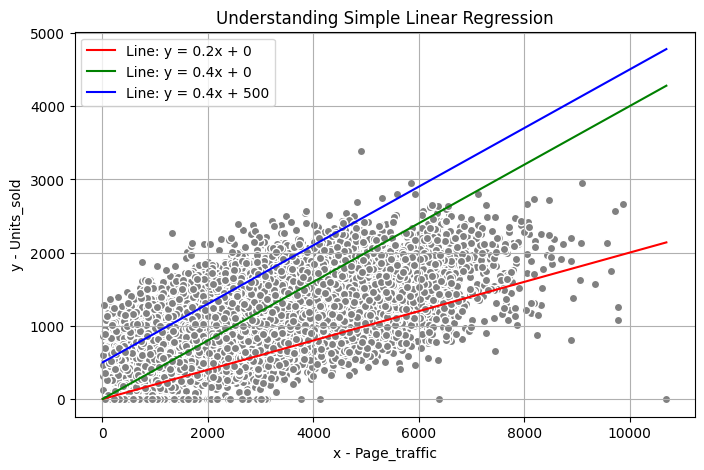

In [10]:
plt.figure(figsize=(8, 5))
plot_SLR_line( m= 0.2, c= 0, clr = 'red')
plot_SLR_line( m = 0.4, c = 0, clr = 'green')
plot_SLR_line(m =  0.4, c = 500,clr =  'blue')
plt.grid()
plt.show()


**But....**  
- Which line fits best?
- How do we know?

We can't just manually try different lines, we **need an ALGORITHM**!

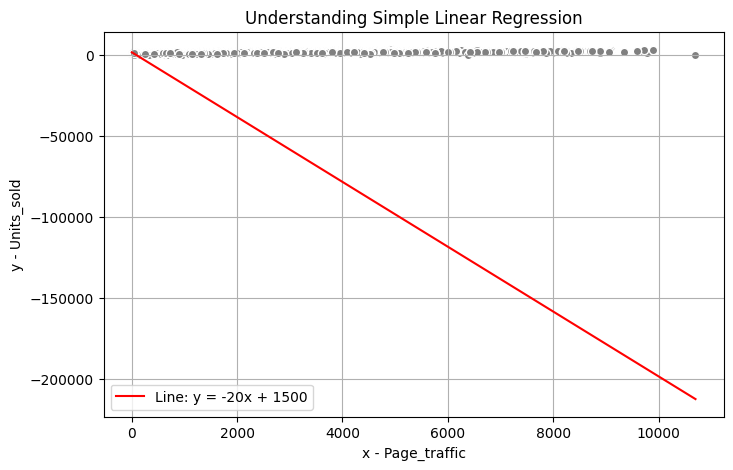

In [11]:
plt.figure(figsize=(8, 5))
plot_SLR_line(m =  -20, c= 1500, clr =  'red', x= 'Page_traffic')
plt.grid()
plt.show()

## Building Simple Linear Regression (Video 4)


**Import the Library**

- *statsmodels* for statistical modeling
- This library gives you detailed regression statistics  

**Why statsmodels?**
- It provides detailed statistical summaries perfect for understanding relationships!

In [12]:
import statsmodels.api as sm

#### Define Variables (X & Y)
- X = Input (what we know)
- Y = Output (what we want to predict)

In [13]:
# Extracting the independent and dependent variables
X = df['Page_traffic']  # Independent Variable (predictor)
Y = df['Units_sold']    # Dependent Variable (target)

#### 🚨 CRITICAL STEP - Add Constant

Before: *X* is just one column of page traffic values
```python
Page_traffic
5835
1881
2477
...
```

In [14]:
# Adding a constant to the independent variable
X = sm.add_constant(X)

After: *X* becomes TWO columns - a constant column of 1's + page traffic

```python
const  Page_traffic
1      5835
1      1881
1      2477
...
```

**Why?**  
Remember the equation: **Y = β₀ + β₁X**
- β₀ = intercept (constant term)
- β₁ = slope (coefficient for X)

Without *add_constant()*, the model would be forced through the origin: Y = β₁X (no intercept!)

#### Fit the Model

1. **sm.OLS(Y, X)**
- OLS = Ordinary Least Squares
- Creates a model object
- Y = Target (what to predict)
- X = Features (what to use for prediction)

2. **.fit()**
- This is where the optimization happens!
-  Calculates the optimal β₀ and β₁ that minimize SSE
-  Uses calculus and linear algebra internally
- Stores the results in model

In [15]:
# Initializing and fitting the model using statsmodels
model = sm.OLS(Y, X).fit()

**Model Learn**:  
```python
Optimal equation: Units_sold = 526.23 + 0.1806 × Page_traffic
                                ↑        ↑
                            intercept  slope
```



#### PREDICTIVE Components
- This is PREDICTIVE - making predictions

In [16]:
# Predicting the Units_sold using the fitted model
predictions = model.predict(X)
predictions

0        1580.289295
1         866.020160
2         973.684400
3        1264.522363
4         787.439716
            ...     
19626    1288.186819
19627    1026.252007
19628    1425.296145
19629    2007.875295
19630    1566.740943
Length: 19631, dtype: float64

#### Visualize Results

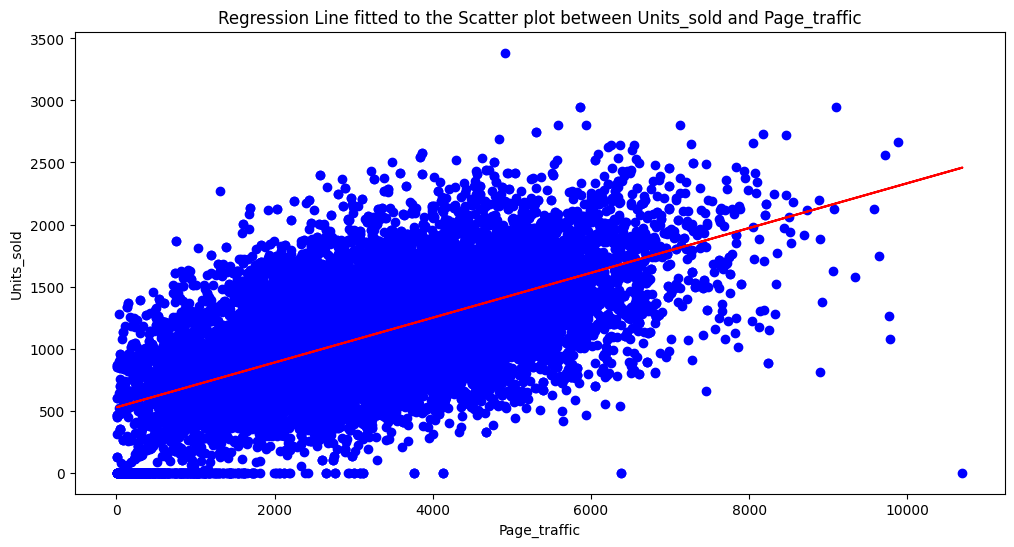

In [17]:
# Plotting the regression line along with the scatter plot
plt.figure(figsize=(12,6))
plt.scatter(df['Page_traffic'], df['Units_sold'], color='blue')

plt.plot(df['Page_traffic'], predictions, color='red')
plt.title('Regression Line fitted to the Scatter plot between Units_sold and Page_traffic')
plt.xlabel('Page_traffic')
plt.ylabel('Units_sold')
plt.show()

Observation:
- Blue dots close to red line = Good predictions ✅
- Blue dots far from red line = Poor predictions (large errors) ❌
- The spread shows model accuracy

#### DESCRIPTIVE Component
- This is DESCRIPTIVE - understanding the relationship


In [18]:
# Extracting the slope and y-intercept of the regression line
intercept = model.params[0]
slope = model.params[1]
slope, intercept

C:\Users\ongja\AppData\Local\Temp\ipykernel_21932\3418734834.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept = model.params[0]
C:\Users\ongja\AppData\Local\Temp\ipykernel_21932\3418734834.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  slope = model.params[1]


(np.float64(0.1806446978524979), np.float64(526.2274833583467))

Observation:
1. **Intercept (526.23)**:
- A product with **ZERO page traffic** would sell ~526 units
- This is the "baseline" sales from other factors (brand reputation, existing customers, etc.)

2. **Slope (0.1806)**:
- For every **1 additional page view**, expect **0.18 more units sold**
- Or: For every **100 page views**, expect **18 more units sold**
- **Positive relationship confirmed!** More traffic → More sales

In [19]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             Units_sold   R-squared:                       0.363
Model:                            OLS   Adj. R-squared:                  0.363
Method:                 Least Squares   F-statistic:                 1.117e+04
Date:                Wed, 18 Feb 2026   Prob (F-statistic):               0.00
Time:                        11:04:30   Log-Likelihood:            -1.4350e+05
No. Observations:               19631   AIC:                         2.870e+05
Df Residuals:                   19629   BIC:                         2.870e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          526.2275      6.145     85.634   

Observation:

**Top Section - Model Quality**  

1. **R² = 0.363 (36.3%)**
    - **Meaning**: Page traffic explains **36.3% of variance** in units sold
    - **The other 63.7%?** Other factors (price, reviews, seasonality, competition, etc.)
    - **Is this good?** Moderate - there's room for improvement with Multiple Regression!

2. **F-statistic = 11,170 (Prob = 0.00)**
    - **Tests**: Is the model meaningful? (vs. just using the mean)
    - **Answer**: YES! (p < 0.001) - The model is highly significant
    - **Interpretation**: Page traffic is **definitely** a useful predictor
3. **No. Observations = 19,631**
    - Large sample size = **Reliable results** ✅
    - More data = More confidence in findings


**Middle Section - Coefficients**  

1. For Intercept (const):
    - coef = 526.23: Baseline sales with zero traffic
    - P>|t| = 0.000: Highly significant (definitely not zero!)
    - [514.18, 538.27]: 95% confident true intercept is in this range

2. For Page_traffic:
    - coef = 0.1806: Effect size (0.18 units per view)
    - std err = 0.002: Very precise estimate!
    - t = 105.688: HUGE t-value = extremely strong evidence
    - P>|t| = 0.000: **Definitely significant** (p < 0.001) ⭐
    - [0.177, 0.184]: 95% confident true slope is between 0.177 and 0.184

**Bottom Section - Diagnostics**  

- **Durbin-Watson** = 2.01: ~2.0 is perfect - no autocorrelation ✅
- **Skew** = 0.166: Close to 0 - residuals fairly normal ✅
- **Omnibus test**: Some deviation from normality (not critical with large n)
